# 01 - Data, labels and causal financial features

Qidian (Martin) Xing. Independent extension with disclosed Codex assistance. The historical period was previously inspected. Source data and row-level predictions are not redistributed.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))
from distress_ml.common import ROOT, PUBLIC, ART
pd.set_option("display.max_columns", 12)
print("Independent extension: saved real-data evidence; no training is triggered.")


Independent extension: saved real-data evidence; no training is triggered.


## Question
What does a row represent, and which information can legitimately enter a model?

## Logic
Audit the pinned snapshot, keep the ultimate-status label interpretation, then register snapshot, ratio and exact-calendar history features. Audit counts are not new model performance.

In [2]:
audit = json.loads((PUBLIC / "data_audit.json").read_text())
print({k: audit[k] for k in ["rows", "companies", "row_label_counts", "company_label_counts", "sequence_audit"]})
display(pd.read_csv(PUBLIC / "split_audit.csv"))

{'rows': 78682, 'companies': 8971, 'row_label_counts': {'failed': 5220, 'alive': 73462}, 'company_label_counts': {'failed': 609, 'alive': 8362}, 'sequence_audit': {'firms_with_at_least_3_rows': 7310, 'firms_with_at_least_4_rows': 6554, 'firms_with_noncontiguous_year_coverage': 710}}


,role,rows,companies,positive_rows,positive_companies,prevalence,year_min,year_max
0,final_fit,59412,7980,4624,591,0.077829,1999,2012
1,calibration,3484,3484,167,167,0.047933,2013,2013
2,decision,3504,3504,142,142,0.040525,2014,2014
3,historical_previously_inspected,12282,3700,287,119,0.023368,2015,2018
4,D1_fit,33052,6601,2810,502,0.085018,1999,2005
5,D1_score,8137,4397,702,389,0.086273,2006,2007
6,D2_fit,41189,7037,3512,544,0.085265,1999,2007
7,D2_score,7600,4034,518,294,0.068158,2008,2009
8,D3_fit,48789,7315,4030,560,0.082601,1999,2009
9,D3_score,7138,3880,412,233,0.057719,2010,2011


Raw units and publication/event dates are unverified. X9 and X16 are identical. Negative financial values are retained. Ratios use positive current denominators and train-role imputation/masks. Exact t-1 absence is never replaced by t-2.

,feature,formula,group,time,set
0,X1,X1,raw_amounts,current fiscal year,S0
1,slog_X1,sign(X1)*log1p(abs(X1)),signed_log_amounts,current fiscal year,S1
2,X2,X2,raw_amounts,current fiscal year,S0
3,slog_X2,sign(X2)*log1p(abs(X2)),signed_log_amounts,current fiscal year,S1
4,X3,X3,raw_amounts,current fiscal year,S0
5,slog_X3,sign(X3)*log1p(abs(X3)),signed_log_amounts,current fiscal year,S1
6,X4,X4,raw_amounts,current fiscal year,S0
7,slog_X4,sign(X4)*log1p(abs(X4)),signed_log_amounts,current fiscal year,S1
8,X5,X5,raw_amounts,current fiscal year,S0
9,slog_X5,sign(X5)*log1p(abs(X5)),signed_log_amounts,current fiscal year,S1


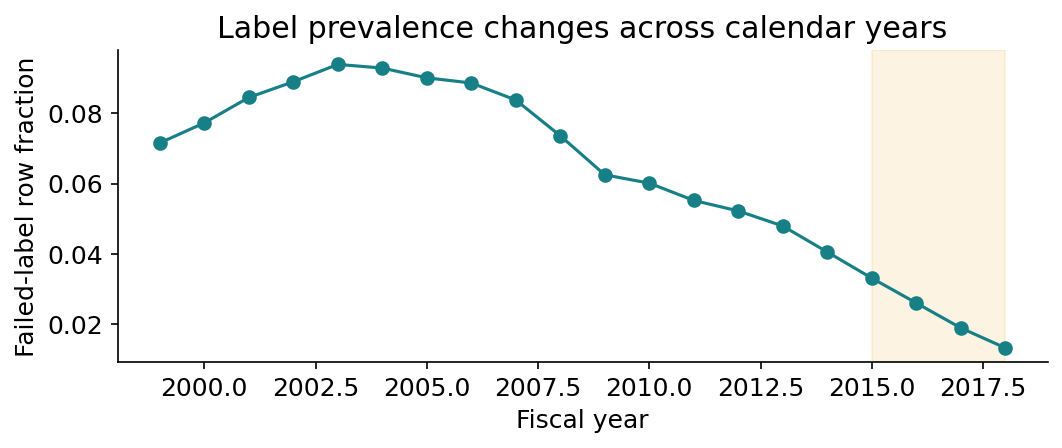

In [3]:
registry = pd.read_csv(PUBLIC / "feature_registry.csv")
display(registry[["feature", "formula", "group", "time", "set"]].head(12))
display(Image(filename=str(PUBLIC / "figures/prevalence.png")))

## Local code verification
The following branch loads only permitted development labels and checks all feature sets retain the same target rows. No raw company identifiers or financial rows are displayed.

In [4]:
from distress_ml.data import load_data
from distress_ml.features import build_features
raw_available = (ROOT.parent / "american_bankruptcy.csv").exists() or bool(__import__("os").environ.get("DISTRESS_DATA"))
if raw_available:
    data = load_data("development")
    shapes = {s: build_features(data, s).shape for s in ["S0", "S1", "S2", "LAGS"]}
    assert len({shape[0] for shape in shapes.values()}) == 1
    print("Development-only feature shapes:", shapes)
else:
    print("Authorized raw snapshot excluded from public release; aggregate audit remains available.")

Authorized raw snapshot excluded from public release; aggregate audit remains available.
